# Time series analysis
## Project 2026

## Environment setup

In [82]:
from tsa_lth.analysis import plotACFnPACF, box_cox
from tsa_lth.modelling import estimateARMA
from tsa_lth.tests import whiteness_test, monti_test
import sys
from scipy.io import loadmat
import scipy.signal
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data"

sys.path.append("..")
from toolbox.timeseries import TimeSeries, verify_white_and_normal

## Data loading

In [83]:
from dataclasses import dataclass

@dataclass
class ProjectData:
    nederbord: TimeSeries
    temperature: TimeSeries
    time: TimeSeries
    waterflow: TimeSeries

def load_project_data() -> ProjectData:
    project_data_raw = loadmat(DATA_DIR / "projectData26.mat")

    project_data = ProjectData(
        project_data_raw["nbdData"].flatten(),
        project_data_raw["tempData"].flatten(),
        np.arange(0, 2000, 1) / 365,
        # project_data_raw["timeData"],
        project_data_raw["waterflowData"].flatten()
    )

    return project_data

project_data = load_project_data()
print(project_data.time)


[0.00000000e+00 2.73972603e-03 5.47945205e-03 ... 5.47123288e+00
 5.47397260e+00 5.47671233e+00]


# Analysis

## Initial model creation

### Transforms

First we plot the initial data, in order to eyeball the properties of the dataset.

Text(0, 0.5, '$m^3/s$')

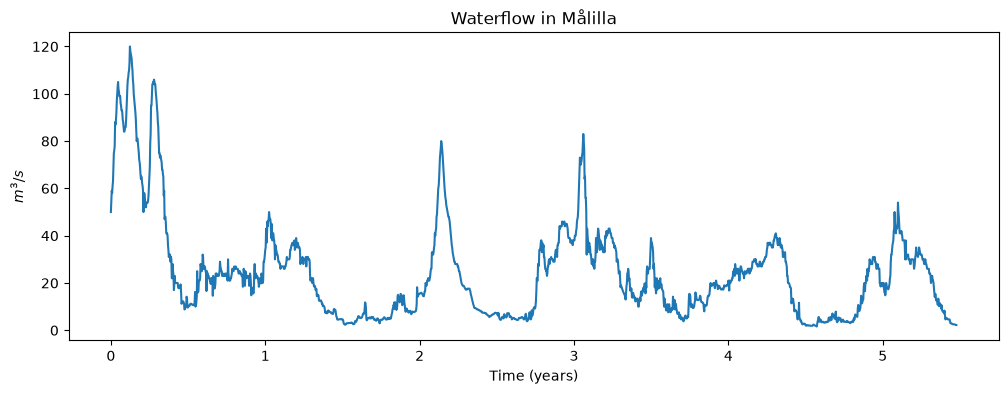

In [84]:
plt.figure(figsize=(12, 4))
plt.plot(project_data.time, project_data.waterflow)
plt.title("Waterflow in Målilla")
plt.xlabel("Time (years)")
plt.ylabel("$m^3/s$")

Clearly the process is not stationary. Can we transform it in some to amend this?

- Clearly subtracting some linear or periodic trend is not suitable. There seems to be no set period, nor  a clear trend.
- The variance is different for different parts of the process. Perhaps we could look at a transform. 
- The data seems to deviate from the mean quite often. A differentiation seems like an apt first tool to try.

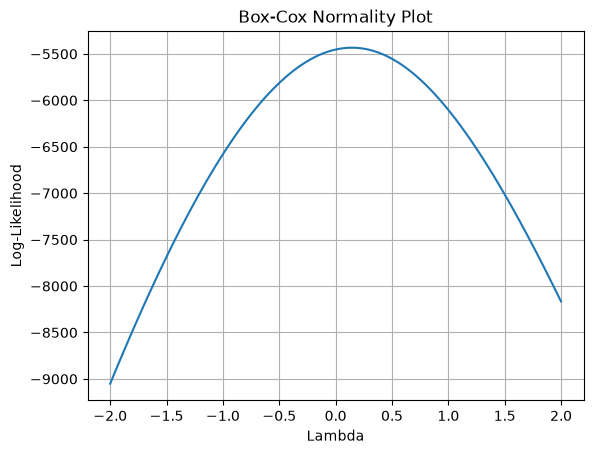

Max Lambda = 0.14454982772227937.
ln(y) could be an appropriate transformation.


In [85]:
box_cox(project_data.waterflow)

It seems like we might need a transform after all...
We try with the log

Text(0.5, 0, 'Time (years)')

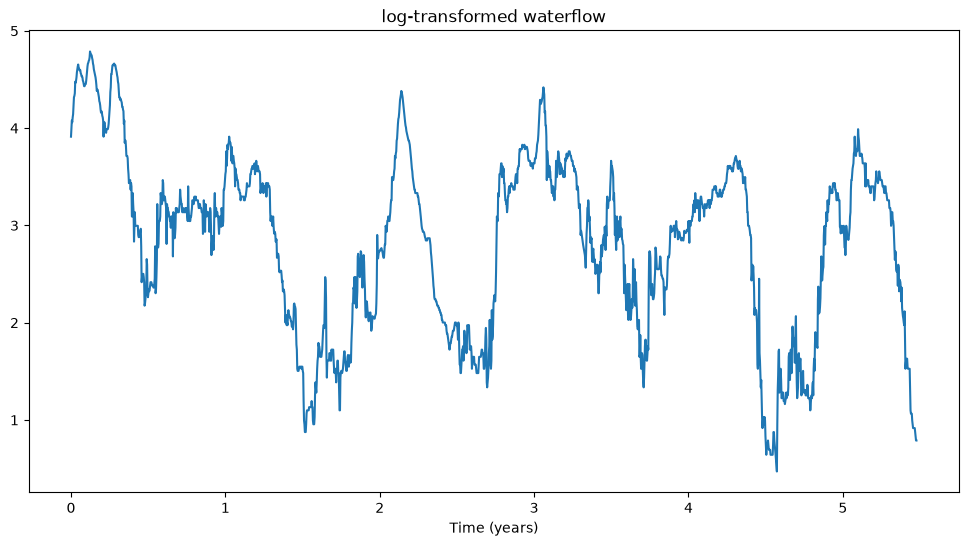

In [86]:
log_waterflow = np.log(project_data.waterflow)

plt.figure(figsize=(12, 6))
plt.plot(project_data.time, log_waterflow)
plt.title("log-transformed waterflow")
plt.xlabel("Time (years)")

Okay, the dataset looks a bit more manageable now.

Text(0.5, 1.0, 'Differentiated waterflow')

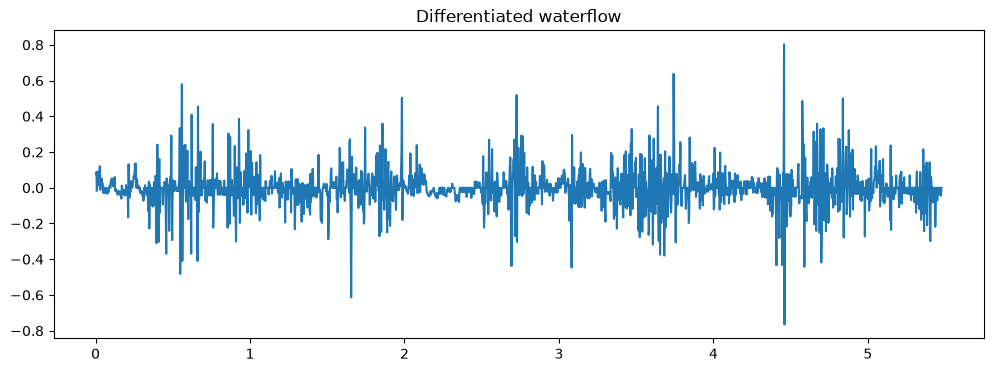

In [87]:
nabla_1 = [1, -1]
nabla_log_waterflow = scipy.signal.lfilter(nabla_1, [1], log_waterflow)[1:]

plt.figure(figsize=(12, 4))
plt.plot(project_data.time[1:], nabla_log_waterflow)
plt.title("Differentiated waterflow")

### Modelling

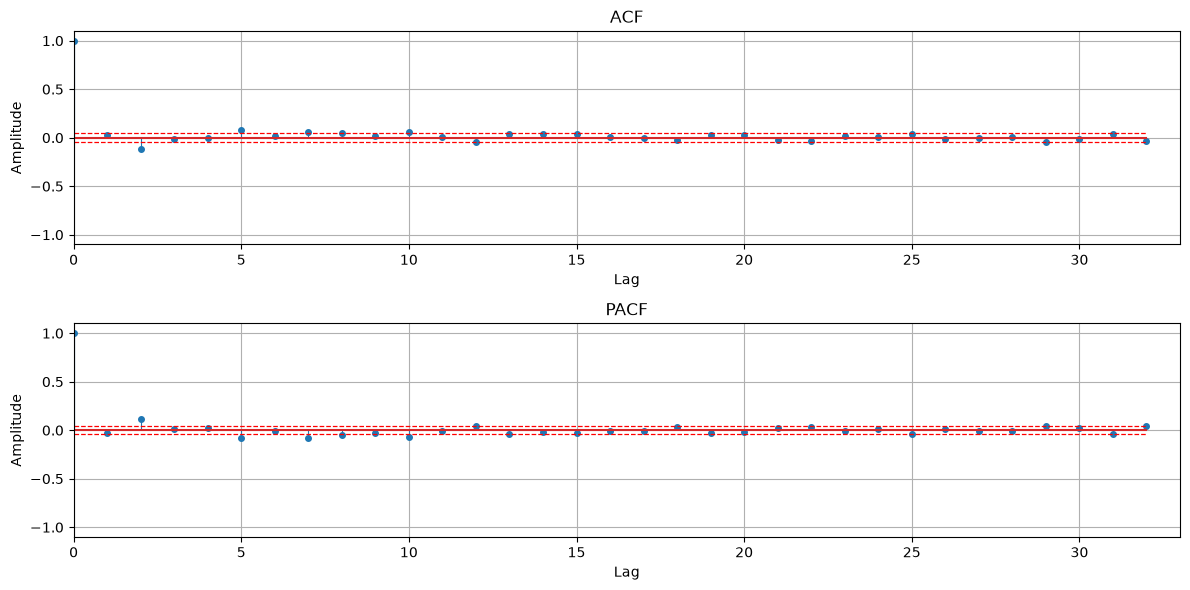

In [93]:
plotACFnPACF(nabla_log_waterflow)

Hmm, we do not have any large values. Perhaps we have already failed, but let's keep trying in order to verify. We start with an AR model with an $a_2$ parameter.

Discrete-time AR model: A(z)y(t) = e(t)

A(z) = 1.0 + 0.1146(±0.0222)·z⁻²

Polynomial orders: nA = 2
Number of free coefficients: 1
Fit to estimation data (NRMSE): 0.63%
FPE : 0.011  MSE : 0.011
AIC : -3428.707   BIC : -3423.108



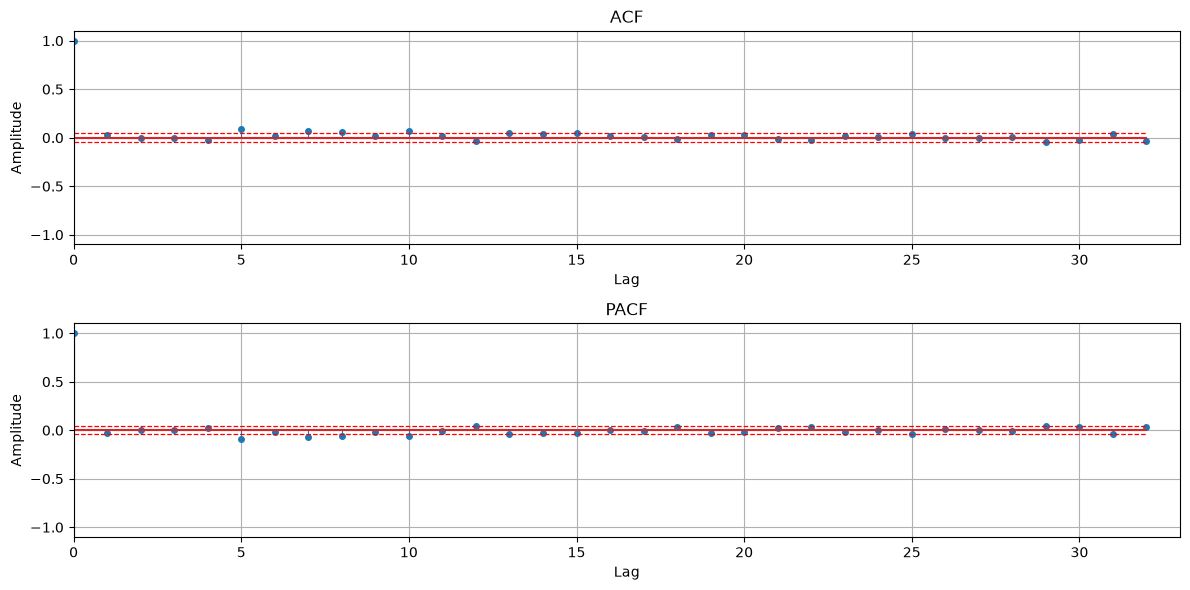

Whiteness test with 5.0% significance
  Ljung-Box-Pierce test: False (white if 69.13 < 36.42)
  McLeod-Li test:        False (white if 315.27 < 36.42)
  Monti test:            False (white if 63.78 < 36.42)
  Sign change test:      False (white if 0.37 in [0.48,0.52])


In [94]:
estimateARMA(nabla_log_waterflow, A=2, A_free=[0, 0, 1])

Discrete-time AR model: A(z)y(t) = e(t)

A(z) = 1.0 + 0.1135(±0.0222)·z⁻² - 0.0797(±0.0222)·z⁻⁵

Polynomial orders: nA = 5
Number of free coefficients: 2
Fit to estimation data (NRMSE): 0.89%
FPE : 0.01  MSE : 0.01
AIC : -3431.879   BIC : -3420.683



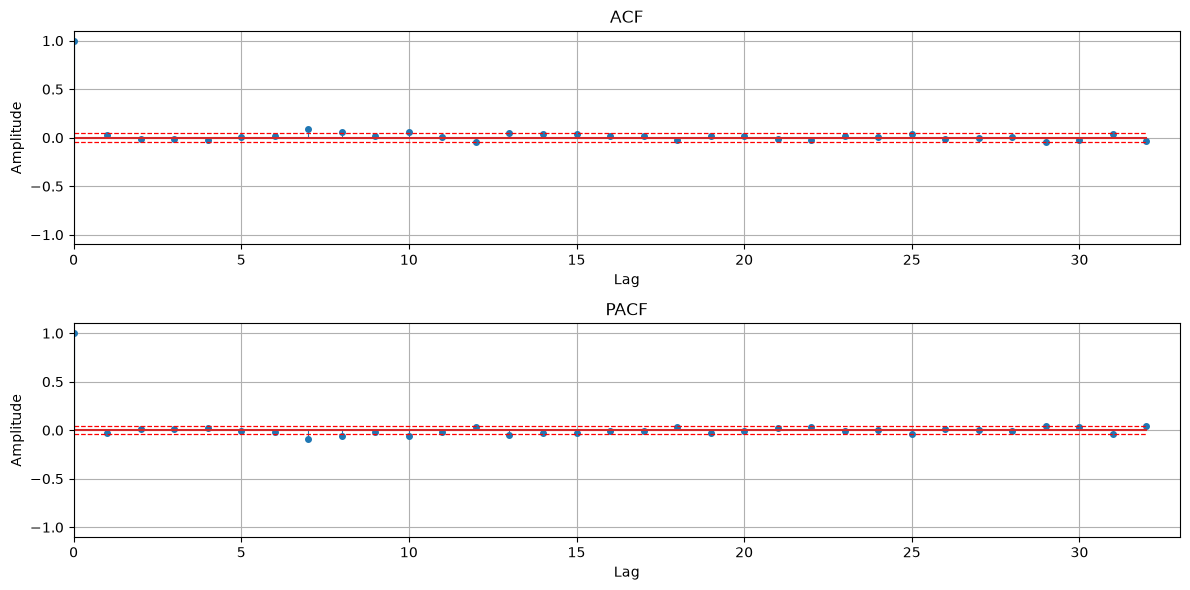

Whiteness test with 5.0% significance
  Ljung-Box-Pierce test: False (white if 53.68 < 36.42)
  McLeod-Li test:        False (white if 302.77 < 36.42)
  Monti test:            False (white if 50.71 < 36.42)
  Sign change test:      False (white if 0.40 in [0.48,0.52])


In [95]:
estimateARMA(nabla_log_waterflow, A=5, A_free=[0, 0, 1, 0, 0, 1])

Hmm, not white – perhaps now we add an MA part?